<a href="https://colab.research.google.com/github/annjerinsundar-code/ICTAK-AI-ML-Coursework/blob/main/Artificial_Neural__Network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [67]:
#Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelBinarizer

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping

# To make the results more reproducible
np.random.seed(42)
tf.random.set_seed(42)

In [68]:
#Loading the Dataset
df = pd.read_csv("/content/mobile_price_classification.csv")

# Display the first five records
df.head()

,battery_power,bluetooth,clock_speed,dual_sim,front_cam,4G,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


In [69]:
#Understanding the dataset

# Number of rows and columns
print("Dataset shape:", df.shape)
print("\n--------------------------------------")

# Column names
print("\nColumn names:")
print(df.columns)
print("\n--------------------------------------")

# Dataset information
print("\nDataset information:")
df.info()

Dataset shape: (2000, 21)

--------------------------------------

Column names:
Index(['battery_power', 'bluetooth', 'clock_speed', 'dual_sim', 'front_cam',
       '4G', 'int_memory', 'm_dep', 'mobile_wt', 'n_cores', 'primary_camera',
       'px_height', 'px_width', 'ram', 'sc_h', 'sc_w', 'talk_time', 'three_g',
       'touch_screen', 'wifi', 'price_range'],
      dtype='object')

--------------------------------------

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   battery_power   2000 non-null   int64  
 1   bluetooth       2000 non-null   int64  
 2   clock_speed     2000 non-null   float64
 3   dual_sim        2000 non-null   int64  
 4   front_cam       2000 non-null   int64  
 5   4G              2000 non-null   int64  
 6   int_memory      2000 non-null   int64  
 7   m_dep           2000 non-null   float

In [70]:
# Statistical description of the dataset
df.describe()

,battery_power,bluetooth,clock_speed,dual_sim,front_cam,4G,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
count,2000.000000,2000.0000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,...,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,1238.518500,0.4950,1.522250,0.509500,4.309500,0.521500,32.046500,0.501750,140.249000,4.520500,...,645.108000,1251.515500,2124.213000,12.306500,5.767000,11.011000,0.761500,0.503000,0.507000,1.500000
std,439.418206,0.5001,0.816004,0.500035,4.341444,0.499662,18.145715,0.288416,35.399655,2.287837,...,443.780811,432.199447,1084.732044,4.213245,4.356398,5.463955,0.426273,0.500116,0.500076,1.118314
min,501.000000,0.0000,0.500000,0.000000,0.000000,0.000000,2.000000,0.100000,80.000000,1.000000,...,0.000000,500.000000,256.000000,5.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000
25%,851.750000,0.0000,0.700000,0.000000,1.000000,0.000000,16.000000,0.200000,109.000000,3.000000,...,282.750000,874.750000,1207.500000,9.000000,2.000000,6.000000,1.000000,0.000000,0.000000,0.750000
50%,1226.000000,0.0000,1.500000,1.000000,3.000000,1.000000,32.000000,0.500000,141.000000,4.000000,...,564.000000,1247.000000,2146.500000,12.000000,5.000000,11.000000,1.000000,1.000000,1.000000,1.500000
75%,1615.250000,1.0000,2.200000,1.000000,7.000000,1.000000,48.000000,0.800000,170.000000,7.000000,...,947.250000,1633.000000,3064.500000,16.000000,9.000000,16.000000,1.000000,1.000000,1.000000,2.250000
max,1998.000000,1.0000,3.000000,1.000000,19.000000,1.000000,64.000000,1.000000,200.000000,8.000000,...,1960.000000,1998.000000,3998.000000,19.000000,18.000000,20.000000,1.000000,1.000000,1.000000,3.000000


In [71]:
# Check the number of missing values in each column
df.isnull().sum()

,0
battery_power,0
bluetooth,0
clock_speed,0
dual_sim,0
front_cam,0
4G,0
int_memory,0
m_dep,0
mobile_wt,0
n_cores,0


In [72]:
# Check for duplicate records
print("Number of duplicate records:", df.duplicated().sum())

Number of duplicate records: 0


In [73]:
# EXPLORATORY DATA ANALYSIS

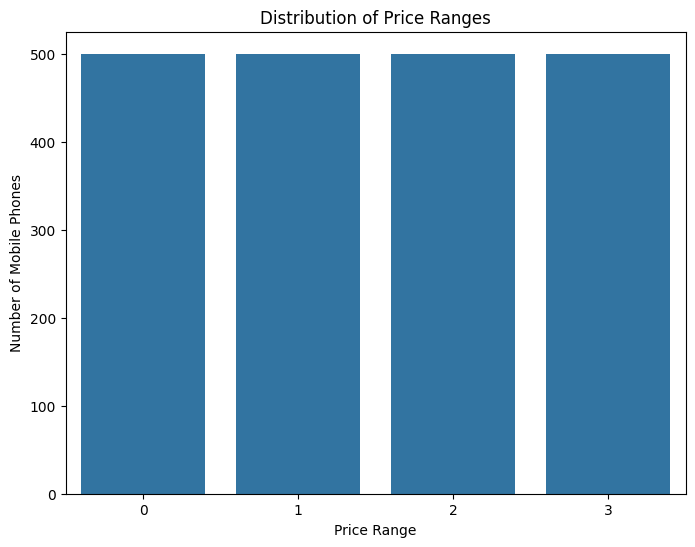

In [74]:
# Distribution of the target variable - price_range
plt.figure(figsize=(8, 6))
sns.countplot(x='price_range', data=df)
plt.title('Distribution of Price Ranges')
plt.xlabel('Price Range')
plt.ylabel('Number of Mobile Phones')
plt.show()


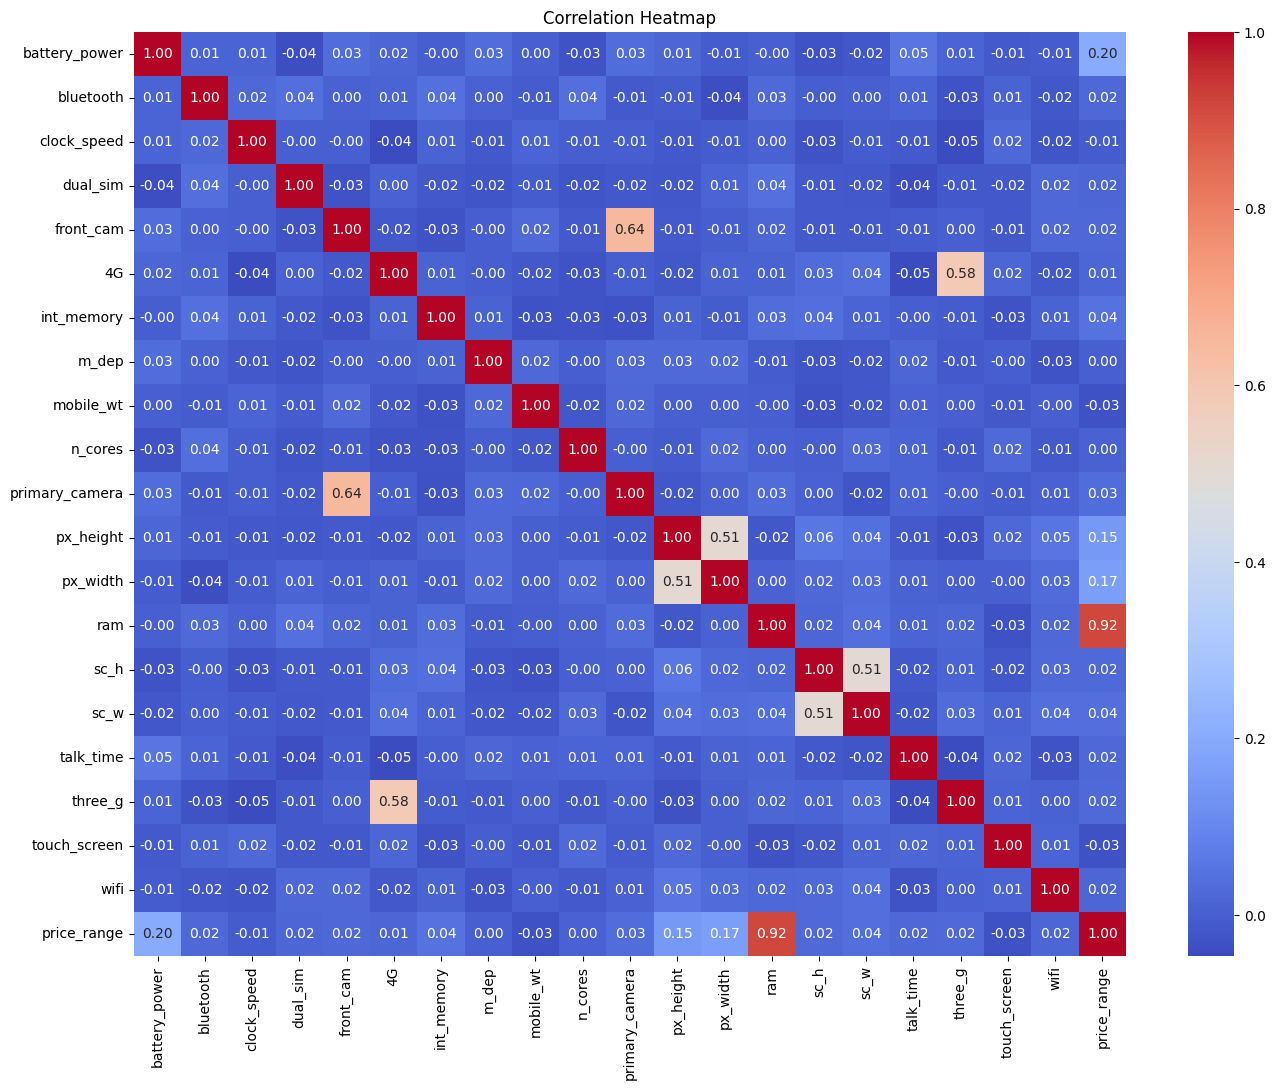

In [75]:
# Correlation heatmap
plt.figure(figsize=(16, 12))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [76]:
# Correlation of each column with price_range
price_correlation = df.corr()["price_range"].sort_values(ascending=False)
price_correlation

,price_range
price_range,1.000000
ram,0.917046
battery_power,0.200723
px_width,0.165818
px_height,0.148858
int_memory,0.044435
sc_w,0.038711
primary_camera,0.033599
three_g,0.023611
sc_h,0.022986


In [77]:
# DATA PREPROCESSING

In [78]:
# Separating Independent and Dependent Variables
X = df.drop("price_range", axis=1)
y = df["price_range"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

Input features shape: (2000, 20)
Target shape: (2000,)


In [79]:
# One-Hot Encoding the Target Labels
lb = LabelBinarizer()
y = lb.fit_transform(y)

print("One-hot encoded target shape:", y.shape)
print("Example encoded label:", y[0])

One-hot encoded target shape: (2000, 4)
Example encoded label: [0 1 0 0]


In [80]:
# Splitting the Dataset
# First, separate the final test set (20%)
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Split the remaining data into training (80% of 80% = 64%) and validation (16%)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.20, random_state=42
)

print("Training data:", X_train.shape, y_train.shape)
print("Validation data:", X_val.shape, y_val.shape)
print("Testing data:", X_test.shape, y_test.shape)

Training data: (1280, 20) (1280, 4)
Validation data: (320, 20) (320, 4)
Testing data: (400, 20) (400, 4)


In [81]:
# Feature Scaling using StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)
print("Scaled training data shape:", X_train.shape)
print("Scaled validation data shape:", X_val.shape)
print("Scaled testing data shape:", X_test.shape)

Scaled training data shape: (1280, 20)
Scaled validation data shape: (320, 20)
Scaled testing data shape: (400, 20)


In [82]:
# Building the Artificial Neural Network
model = Sequential([
    Dense(128, input_shape=(X_train.shape[1],), activation="relu"),  # Hidden layer 1
    Dense(64, activation="relu"),                                   # Hidden layer 2
    Dense(4, activation="softmax")                                  # Output layer: 4 classes
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_34 (Dense)                │ (None, 128)            │         2,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_36 (Dense)                │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,204 (43.77 KB)

 Trainable params: 11,204 (43.77 KB)

 Non-trainable params: 0 (0.00 B)

In [83]:
# Compiling the ANN Model

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [84]:
# Training the ANN Model

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4008 - loss: 1.2739 - val_accuracy: 0.5781 - val_loss: 1.0779
Epoch 2/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6703 - loss: 0.9294 - val_accuracy: 0.7219 - val_loss: 0.7708
Epoch 3/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8016 - loss: 0.6598 - val_accuracy: 0.7906 - val_loss: 0.5662
Epoch 4/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8828 - loss: 0.4819 - val_accuracy: 0.8562 - val_loss: 0.4395
Epoch 5/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9141 - loss: 0.3645 - val_accuracy: 0.8656 - val_loss: 0.3558
Epoch 6/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9398 - loss: 0.2829 - val_accuracy: 0.8813 - val_loss: 0.2993
Epoch 7/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9570 - loss: 0.2249 - val_accuracy: 0.8969 - val_loss: 0.2600
Epoch 8/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9641 - loss: 0.1826 - val_accuracy: 0.9062 - v

In [85]:
# Evaluating the ANN Model

loss, acc = model.evaluate(X_test, y_test, verbose=1)

print("Test Loss:", loss)
print("Test Accuracy:", acc)

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9250 - loss: 0.1832  
Test Loss: 0.18315567076206207
Test Accuracy: 0.925000011920929


In [86]:
# Visualising Model Performance

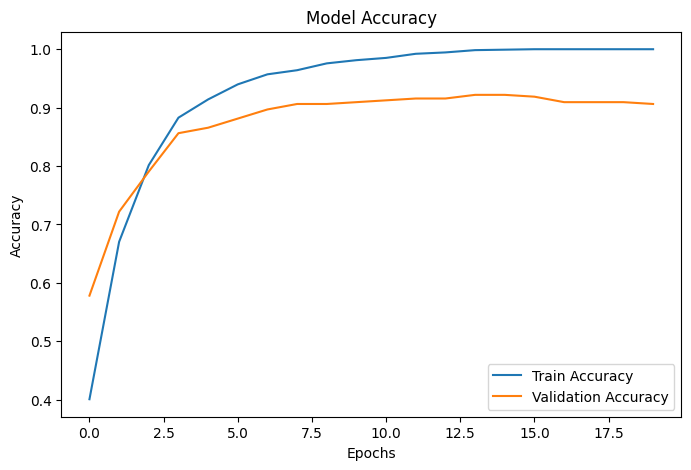

In [87]:
# Training and Validation Accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Model Accuracy")
plt.legend()
plt.show()

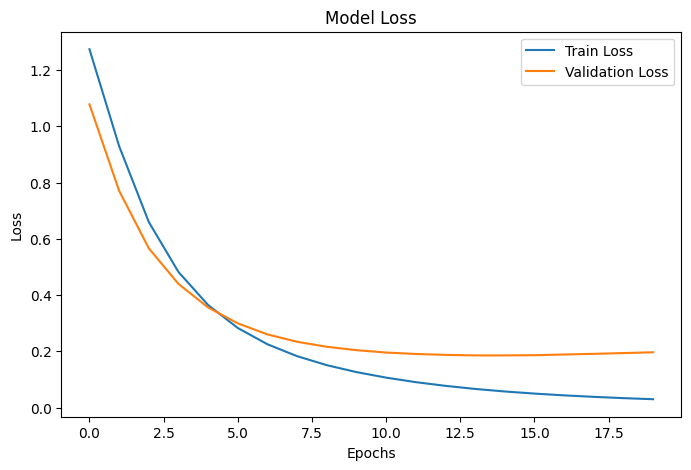

In [88]:
# Training and Validation Loss

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Model Loss")
plt.legend()
plt.show()

In [89]:
# Hyperparameter Tuning
def build_ann(hidden_layers, optimizer="adam"):
    layers = [Dense(hidden_layers[0], input_shape=(X_train.shape[1],), activation="relu")]

    for neurons in hidden_layers[1:]:
        layers.append(Dense(neurons, activation="relu"))

    layers.append(Dense(4, activation="softmax"))

    tuning_model = Sequential(layers)
    tuning_model.compile(
        optimizer=optimizer,
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return tuning_model

In [90]:
# Define the Configurations
configurations = [
    {"name": "One hidden layer (64 neurons), Adam", "layers": [64], "optimizer": "adam"},
    {"name": "Two hidden layers (128, 64), Adam", "layers": [128, 64], "optimizer": "adam"},
    {"name": "Two hidden layers (128, 64), RMSprop", "layers": [128, 64], "optimizer": "rmsprop"},
    {"name": "Two hidden layers (128, 64), SGD", "layers": [128, 64], "optimizer": "sgd"}
]

tuning_results = []

for config in configurations:
    print("\nTraining:", config["name"])

    tuning_model = build_ann(
        hidden_layers=config["layers"],
        optimizer=config["optimizer"]
    )

    tuning_history = tuning_model.fit(
        X_train, y_train,
        epochs=50,
        batch_size=32,
        validation_data=(X_val, y_val),
        verbose=0
    )

    best_val_accuracy = max(tuning_history.history["val_accuracy"])
    best_val_loss = min(tuning_history.history["val_loss"])

    tuning_results.append({
        "Configuration": config["name"],
        "Best Validation Accuracy": best_val_accuracy,
        "Lowest Validation Loss": best_val_loss
    })

    print("Best validation accuracy:", round(best_val_accuracy, 4))
    print("Lowest validation loss:", round(best_val_loss, 4))


Training: One hidden layer (64 neurons), Adam
Best validation accuracy: 0.9125
Lowest validation loss: 0.2027

Training: Two hidden layers (128, 64), Adam
Best validation accuracy: 0.9062
Lowest validation loss: 0.2084

Training: Two hidden layers (128, 64), RMSprop
Best validation accuracy: 0.9062
Lowest validation loss: 0.2126

Training: Two hidden layers (128, 64), SGD
Best validation accuracy: 0.9125
Lowest validation loss: 0.2532


In [91]:
# Compare the Tuning Results

tuning_results_df = pd.DataFrame(tuning_results)
tuning_results_df.sort_values(
    by="Best Validation Accuracy",
    ascending=False
).reset_index(drop=True)


,Configuration,Best Validation Accuracy,Lowest Validation Loss
0,"One hidden layer (64 neurons), Adam",0.91250,0.202685
1,"Two hidden layers (128, 64), SGD",0.91250,0.253169
2,"Two hidden layers (128, 64), Adam",0.90625,0.208394
3,"Two hidden layers (128, 64), RMSprop",0.90625,0.212550


In [92]:
# Select the Best Configuration

best_result = tuning_results_df.sort_values(
    by="Best Validation Accuracy",
    ascending=False
).iloc[0]

print("Best configuration:")
print(best_result["Configuration"])
print("Best validation accuracy:", best_result["Best Validation Accuracy"])
print("Lowest validation loss:", best_result["Lowest Validation Loss"])


Best configuration:
One hidden layer (64 neurons), Adam
Best validation accuracy: 0.9125000238418579
Lowest validation loss: 0.20268464088439941


In [93]:
# Building and Training the Final ANN Model

best_config = next(
    config for config in configurations
    if config["name"] == best_result["Configuration"]
)

final_model = build_ann(
    hidden_layers=best_config["layers"],
    optimizer=best_config["optimizer"]
)

final_early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

final_history = final_model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[final_early_stop],
    verbose=1
)

Epoch 1/100


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.3008 - loss: 1.4314 - val_accuracy: 0.3281 - val_loss: 1.3634
Epoch 2/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4305 - loss: 1.2437 - val_accuracy: 0.4250 - val_loss: 1.2037
Epoch 3/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5320 - loss: 1.1094 - val_accuracy: 0.5437 - val_loss: 1.0788
Epoch 4/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6234 - loss: 0.9951 - val_accuracy: 0.5844 - val_loss: 0.9723
Epoch 5/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6859 - loss: 0.8962 - val_accuracy: 0.6469 - val_loss: 0.8810
Epoch 6/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7320 - loss: 0.8113 - val_accuracy: 0.7031 - val_loss: 0.8037
Epoch 7/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7734 - loss: 0.7389 - val_accuracy: 0.7250 - val_loss: 0.7385
Epoch 8/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8039 - loss: 0.6766 - val_accuracy: 0.7656 - val_loss: 0.6

In [94]:
#Final Model Evaluation
final_loss, final_acc = final_model.evaluate(X_test, y_test, verbose=1)

print("Final Test Loss:", final_loss)
print("Final Test Accuracy:", final_acc)

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9475 - loss: 0.1541  
Final Test Loss: 0.15409106016159058
Final Test Accuracy: 0.9474999904632568


In [95]:
# Visualizing the Final Model Performance

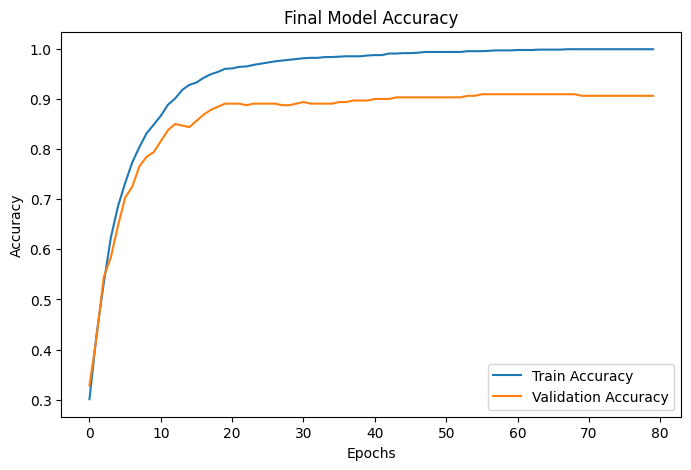

In [96]:
plt.figure(figsize=(8, 5))
plt.plot(final_history.history["accuracy"], label="Train Accuracy")
plt.plot(final_history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Final Model Accuracy")
plt.legend()
plt.show()

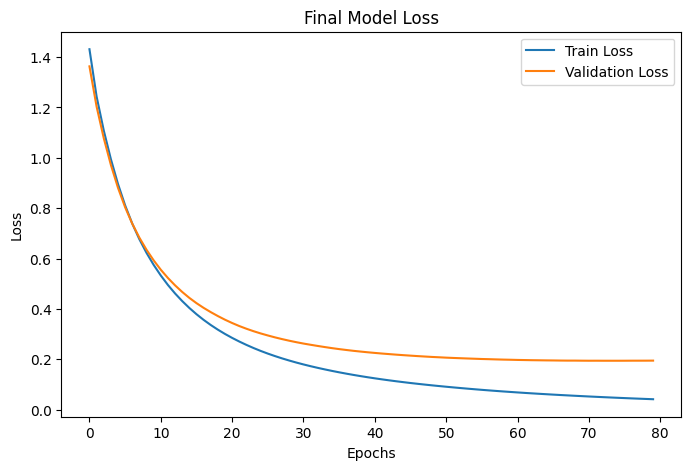

In [97]:
plt.figure(figsize=(8, 5))
plt.plot(final_history.history["loss"], label="Train Loss")
plt.plot(final_history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Final Model Loss")
plt.legend()
plt.show()

In [98]:
# Predicting the price range of a New Mobile Phone

In [99]:
# Example: use one record from the test set as an unseen sample
X_new = X_test[0].reshape(1, -1)

y_new_pred = final_model.predict(X_new)

print("Predicted probabilities:", y_new_pred)
print("Predicted price range:", np.argmax(y_new_pred))
print("Actual price range:", np.argmax(y_test[0]))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
Predicted probabilities: [[9.8823988e-01 1.1760130e-02 5.3325184e-08 7.0929688e-19]]
Predicted price range: 0
Actual price range: 0


The ANN model successfully predicted the price range of the selected mobile phone. The model assigned the highest probability (98.87%) to price range 0, which matches the actual price range. This demonstrates that the trained model can correctly classify this particular unseen sample.